# Sonora — perfis acústicos de São Paulo com KMeans + PCA

Pergunta de ML: **as medições reais de ruído feitas por cidadãos em São Paulo
formam perfis acústicos distintos e interpretáveis?**

Fonte: NoiseCapture (Universidade Gustave Eiffel / CNRS), dump público
`Brazil.zip`, licença ODbL. Uma linha do modelo = uma sessão de medição.

Execução (a partir da raiz do repositório):
    python ml/sonora_clusters.py

Este .py é a fonte. O notebook executado `sonora_clusters.ipynb` é gerado a
partir dele (ver ml/README.md), com as mesmas células `# %%`.

In [1]:
from __future__ import annotations

import hashlib
import itertools
import json
import re
import zipfile
from pathlib import Path

import matplotlib

try:  # no Jupyter os gráficos aparecem inline; no terminal só são salvos
    get_ipython  # type: ignore[name-defined]  # noqa: B018
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# No notebook não existe __file__; o kernel roda com a pasta ml/ como diretório atual.
ML_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
ROOT = ML_DIR.parent
RAW_ZIP = ML_DIR / "dados" / "raw" / "noisecapture-brazil.zip"
FIG_DIR = ML_DIR / "figuras"
OUT_DIR = ML_DIR / "output"
SCHEMA = ROOT / "contracts" / "schemas" / "ml-summary.schema.json"
SOURCE_URL = "https://data.noise-planet.org/dump/Brazil.zip"
EXPECTED_SHA256 = "540aef978fd95a0fcb9e09a2a59bf91ba0ee98b2a85d771f3d7f6580181df9aa"

SEED = 42
TZ = "America/Sao_Paulo"

# Filtros técnicos (justificados no dados/README.md)
MAX_GPS_ACCURACY_M = 50  # precisão do GPS pior que isso não localiza a sessão
MIN_POINTS_PER_SESSION = 30  # ~30 s de medição válida
EXCLUDED_TAGS = {"indoor", "test"}  # queremos ruído ambiente externo
MIN_SESSION_STD_DB = 0.5  # sinal quase constante = sensor travado/saturado
CELL_DEG = 0.0045  # ~500 m de latitude; unidade espacial da divisão
TEST_FRACTION = 0.20
N_FOLDS = 5

FEATURES = ["laeq", "p10", "p50", "p90", "std"]
FEATURE_LABELS = {
    "laeq": "LAeq (média energética)",
    "p10": "p10 (níveis baixos)",
    "p50": "p50 (mediana)",
    "p90": "p90 (picos)",
    "std": "desvio-padrão",
}

FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


def save(fig: plt.Figure, name: str) -> None:
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=120)
    print(f"  figura: ml/figuras/{name}")
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close(fig)

## 1. Dados reais: integridade e leitura

In [2]:
sha = hashlib.sha256(RAW_ZIP.read_bytes()).hexdigest()
print("SHA-256 do dump:", sha)
assert sha == EXPECTED_SHA256, "Arquivo diferente do snapshot documentado em dados/README.md"

with zipfile.ZipFile(RAW_ZIP) as z:
    # Os nomes no ZIP têm acentuação corrompida ("S?o Paulo"); casamos por padrão.
    def pick(kind: str) -> str:
        pattern = rf"Brazil_S.o Paulo_S.o Paulo\.{kind}\.geojson"
        return next(n for n in z.namelist() if re.fullmatch(pattern, n))

    points_geo = json.loads(z.read(pick("points")))
    tracks_geo = json.loads(z.read(pick("tracks")))

points = pd.DataFrame(
    {
        "track": f["properties"]["pk_track"],
        "lon": f["geometry"]["coordinates"][0],
        "lat": f["geometry"]["coordinates"][1],
        "epoch_ms": f["properties"]["time_epoch"],
        "db": f["properties"]["noise_level"],
        "accuracy": f["properties"]["accuracy"],
    }
    for f in points_geo["features"]
)
tracks = pd.DataFrame(
    {
        "track": f["properties"]["pk_track"],
        "tags": f["properties"]["tags"] or [],
        "gain_calibration": f["properties"]["gain_calibration"],
    }
    for f in tracks_geo["features"]
)
del points_geo, tracks_geo

print(f"Pontos brutos: {len(points):,} | sessões brutas: {points.track.nunique():,}")
print(points.describe().T[["count", "mean", "min", "50%", "max"]])

SHA-256 do dump: 540aef978fd95a0fcb9e09a2a59bf91ba0ee98b2a85d771f3d7f6580181df9aa


Pontos brutos: 282,021 | sessões brutas: 1,894
             count          mean           min           50%           max
track     282021.0  5.067364e+05  2.273000e+03  5.398410e+05  6.410810e+05
lon       282021.0 -4.665201e+01 -4.679203e+01 -4.666015e+01 -4.637552e+01
lat       282021.0 -2.356063e+01 -2.383062e+01 -2.355819e+01 -2.343651e+01
epoch_ms  282021.0  1.701876e+12  1.491960e+12  1.716993e+12  1.752198e+12
db        282021.0  5.127380e+01  0.000000e+00  4.967860e+01  1.158587e+02
accuracy  282021.0  4.162249e+01  1.000000e+00  1.136300e+01  1.002852e+04


## 2. Limpeza (cada filtro é registrado)

In [3]:
cleaning_log: list[dict] = []


def log_step(name: str, df: pd.DataFrame) -> None:
    cleaning_log.append({"etapa": name, "pontos": len(df), "sessoes": df.track.nunique()})


log_step("dados brutos", points)

pts = points[np.isfinite(points.db) & (points.db > 0)]
log_step("remove nível <= 0 dB (sentinela)", pts)

pts = pts[pts.accuracy <= MAX_GPS_ACCURACY_M]
log_step(f"remove GPS com precisão > {MAX_GPS_ACCURACY_M} m", pts)

pts = pts.drop_duplicates(subset=["track", "epoch_ms"])
log_step("remove pontos duplicados (mesma sessão e segundo)", pts)

excluded_tracks = set(tracks[tracks.tags.apply(lambda t: bool(EXCLUDED_TAGS & set(t)))].track)
pts = pts[~pts.track.isin(excluded_tracks)]
log_step("remove sessões marcadas 'indoor' ou 'test'", pts)

counts = pts.groupby("track").size()
pts = pts[pts.track.isin(counts[counts >= MIN_POINTS_PER_SESSION].index)]
log_step(f"remove sessões com < {MIN_POINTS_PER_SESSION} pontos", pts)

cleaning = pd.DataFrame(cleaning_log)
print(cleaning.to_string(index=False))
cleaning.to_csv(OUT_DIR / "limpeza.csv", index=False)

                                            etapa  pontos  sessoes
                                     dados brutos  282021     1894
                 remove nível <= 0 dB (sentinela)  281946     1894
                   remove GPS com precisão > 50 m  257792     1823
remove pontos duplicados (mesma sessão e segundo)  255202     1823
       remove sessões marcadas 'indoor' ou 'test'  233223     1522
                   remove sessões com < 30 pontos  230046     1230

## 3. Uma linha por sessão (features acústicas)

Cada ponto do NoiseCapture é o nível equivalente de 1 s. Segundos da mesma
sessão são correlacionados, por isso a unidade amostral é a **sessão**.
LAeq usa média energética: 10·log10(média(10^(L/10))) — nunca média aritmética
de dB. `p90` aqui é o percentil numérico 90 (níveis altos), o oposto da
convenção acústica L90.

Sessões com sinal constante removidas: 45
Sessões finais: 1,185 em 199 células de ~500 m
          laeq      p10      p50      p90      std  n_points
count  1185.00  1185.00  1185.00  1185.00  1185.00   1185.00
mean     60.26    52.83    56.57    62.33     4.03    192.78
std      11.56    11.36    11.78    11.97     2.12    509.21
min      29.20    16.35    24.43    30.02     0.51     30.00
25%      53.54    46.30    49.76    55.59     2.58     61.00
50%      59.35    51.78    55.81    61.77     3.74     65.00
75%      66.57    58.98    62.87    68.66     5.07    108.00
max     110.45   108.89   110.48   111.51    17.96   6405.00
Sessões por ano: {2017: 7, 2018: 43, 2019: 17, 2020: 2, 2022: 42, 2023: 575, 2024: 460, 2025: 39}
Maiores células: {'-5236_-10385': 362, '-5236_-10386': 202, '-5234_-10350': 64, '-5233_-10369': 34, '-5236_-10383': 31}


  figura: ml/figuras/01_exploracao.png


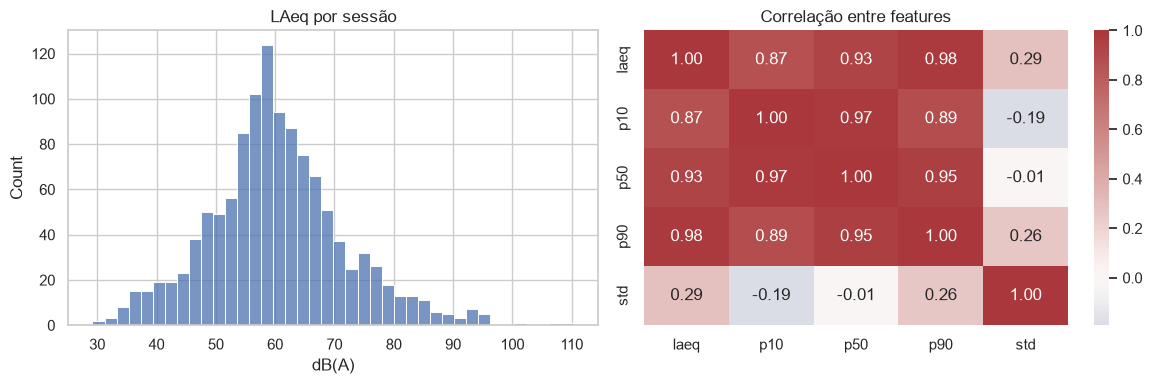

In [4]:
def session_features(g: pd.DataFrame) -> pd.Series:
    db = g.db.to_numpy()
    return pd.Series(
        {
            "laeq": 10 * np.log10(np.mean(10 ** (db / 10))),
            "p10": np.percentile(db, 10),
            "p50": np.percentile(db, 50),
            "p90": np.percentile(db, 90),
            "std": db.std(ddof=1),
            "n_points": len(db),
            "lat": g.lat.median(),
            "lon": g.lon.median(),
            "start_ms": g.epoch_ms.min(),
            "end_ms": g.epoch_ms.max(),
        }
    )


sessions = pts.groupby("track")[["db", "lat", "lon", "epoch_ms"]].apply(session_features)
sessions = sessions.join(tracks.set_index("track")[["tags", "gain_calibration"]])

# Sessões com variação < 0,5 dB (ex.: 93 dB constantes por 30 s) não são som
# ambiente real; são falhas de sensor. Filtro aplicado já na sessão.
flat = sessions["std"] < MIN_SESSION_STD_DB
sessions = sessions[~flat]
cleaning_log.append({"etapa": f"remove sessões com desvio < {MIN_SESSION_STD_DB} dB (sinal constante)",
                     "pontos": int(sessions.n_points.sum()), "sessoes": len(sessions)})
cleaning = pd.DataFrame(cleaning_log)
cleaning.to_csv(OUT_DIR / "limpeza.csv", index=False)
print(f"Sessões com sinal constante removidas: {int(flat.sum())}")
start_local = pd.to_datetime(sessions.start_ms, unit="ms", utc=True).dt.tz_convert(TZ)
sessions["hour"] = start_local.dt.hour
sessions["year"] = start_local.dt.year
sessions["cell"] = (
    np.floor(sessions.lat / CELL_DEG).astype(int).astype(str)
    + "_"
    + np.floor(sessions.lon / CELL_DEG).astype(int).astype(str)
)
print(f"Sessões finais: {len(sessions):,} em {sessions.cell.nunique()} células de ~500 m")
print(sessions[FEATURES + ["n_points"]].describe().round(2))
print("Sessões por ano:", sessions.year.value_counts().sort_index().to_dict())
print("Maiores células:", sessions.cell.value_counts().head(5).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(sessions.laeq, bins=40, ax=axes[0])
axes[0].set(title="LAeq por sessão", xlabel="dB(A)")
sns.heatmap(sessions[FEATURES].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set(title="Correlação entre features")
save(fig, "01_exploracao.png")

## 4. Divisão treino/teste por região (sem vazamento)

Sessões do mesmo lugar são parecidas. Se uma rua estiver no treino e no teste,
o teste fica otimista. Por isso o teste é formado por **células inteiras de
~500 m**, sorteadas até somar ~20% das sessões. Nenhuma transformação é
ajustada antes desta divisão. A célula dominante (≈1/3 dos dados) não cabe
nos 20% e fica no treino; o teste mede então generalização para **regiões
novas**, que é o que importa para quem consulta um endereço desconhecido.

Treino: 948 sessões / 130 células | Teste: 237 sessões / 69 células (20.0%)


  figura: ml/figuras/02_divisao_espacial.png


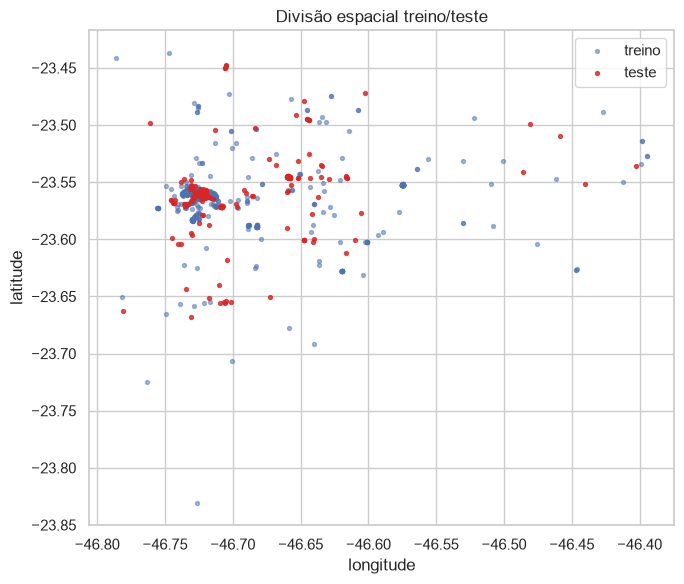

In [5]:
def spatial_holdout(df: pd.DataFrame, frac: float, seed: int) -> pd.Series:
    rng = np.random.default_rng(seed)
    sizes = df.cell.value_counts()
    budget = frac * len(df)
    chosen, total = [], 0
    for cell in rng.permutation(sizes.index.to_numpy()):
        if total + sizes[cell] <= budget * 1.05:
            chosen.append(cell)
            total += sizes[cell]
        if total >= budget:
            break
    return df.cell.isin(chosen)


is_test = spatial_holdout(sessions, TEST_FRACTION, SEED)
train, test = sessions[~is_test].copy(), sessions[is_test].copy()
assert not set(train.cell) & set(test.cell)
print(
    f"Treino: {len(train)} sessões / {train.cell.nunique()} células | "
    f"Teste: {len(test)} sessões / {test.cell.nunique()} células "
    f"({len(test) / len(sessions):.1%})"
)
X_train, X_test = train[FEATURES].to_numpy(), test[FEATURES].to_numpy()

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(train.lon, train.lat, s=8, alpha=0.5, label="treino")
ax.scatter(test.lon, test.lat, s=8, alpha=0.8, label="teste", color="tab:red")
ax.set(title="Divisão espacial treino/teste", xlabel="longitude", ylabel="latitude")
ax.legend()
save(fig, "02_divisao_espacial.png")

## 5. Modelo e busca de hiperparâmetros

Por que KMeans + PCA: não existe rótulo "bom/ruim" confiável para um lugar;
inventar um rótulo seria pior do que deixar os dados se agruparem. As 5
features são muito correlacionadas, então o PCA resume intensidade e variação
em poucos eixos antes do KMeans.

Pipeline: StandardScaler → PCA → KMeans, ajustado **só** no treino de cada fold.
Grade: n_clusters {2,3,4,5} × n_components {2,3} × whiten {não, sim}
= 16 combinações. `whiten` iguala o peso dos eixos do PCA: sem ele, o KMeans
separa quase só por intensidade (PC1); com ele, a variação (PC2) pesa igual.
Validação cruzada: GroupKFold(5) por célula, só no treino.

Métricas (no espaço padronizado das 5 features, para comparar PCA 2 vs 3 de
forma justa): silhouette (↑, de -1 a 1), Davies–Bouldin (↓) e distância média
ao centro do grupo (↓, em desvios-padrão).

 n_clusters  n_components  whiten  sil_treino  sil_val  sil_val_std  db_treino  db_val  dist_val
          2             2   False       0.405    0.407        0.117      0.939   0.919     1.610
          2             3   False       0.405    0.407        0.117      0.939   0.919     1.618
          2             2    True       0.335    0.373        0.090      1.200   1.030     1.091
          4             2   False       0.390    0.345        0.058      0.896   0.936     1.285
          4             3   False       0.390    0.345        0.058      0.896   0.936     1.293
          3             2    True       0.347    0.336        0.068      1.103   1.094     0.950
          3             2   False       0.373    0.336        0.096      0.929   0.925     1.337
          3             3   False       0.373    0.336        0.096      0.928   0.925     1.346
          5             2    True       0.337    0.332        0.048      0.985   0.974     0.751
          5             2   Fa

  figura: ml/figuras/03_busca_hiperparametros.png


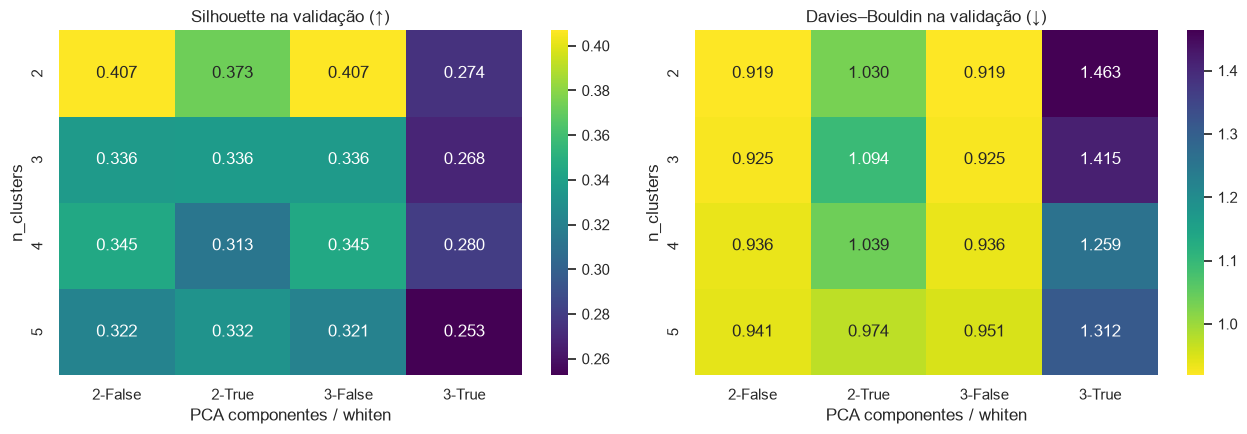

  figura: ml/figuras/04_cv_por_k.png


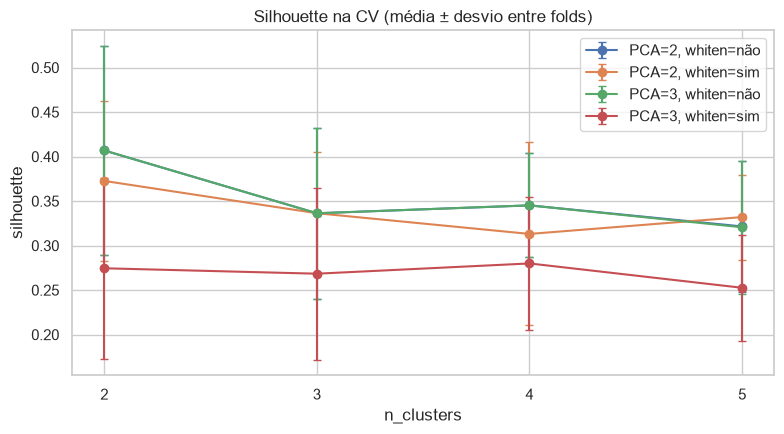

In [6]:
def build_pipeline(k: int, n_comp: int, whiten: bool, seed: int = SEED) -> Pipeline:
    return Pipeline(
        [
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=n_comp, whiten=whiten, random_state=seed)),
            ("kmeans", KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=seed)),
        ]
    )


def evaluate(pipe: Pipeline, X: np.ndarray) -> dict:
    """Avalia um pipeline já ajustado sobre X (treino ou dados novos)."""
    labels = pipe.predict(X)
    Z = pipe.named_steps["scaler"].transform(X)
    dist = pipe[:-1].transform(X)
    centers = pipe.named_steps["kmeans"].cluster_centers_
    mean_dist = float(np.mean(np.linalg.norm(dist - centers[labels], axis=1)))
    if len(np.unique(labels)) < 2:
        return {"silhouette": np.nan, "davies_bouldin": np.nan, "mean_dist": mean_dist}
    return {
        "silhouette": float(silhouette_score(Z, labels)),
        "davies_bouldin": float(davies_bouldin_score(Z, labels)),
        "mean_dist": mean_dist,
    }


grid = list(itertools.product([2, 3, 4, 5], [2, 3], [False, True]))
cv = GroupKFold(n_splits=N_FOLDS)
rows = []
for k, n_comp, whiten in grid:
    fold_tr, fold_va = [], []
    for tr_idx, va_idx in cv.split(X_train, groups=train.cell):
        pipe = build_pipeline(k, n_comp, whiten).fit(X_train[tr_idx])
        fold_tr.append(evaluate(pipe, X_train[tr_idx]))
        fold_va.append(evaluate(pipe, X_train[va_idx]))
    tr, va = pd.DataFrame(fold_tr), pd.DataFrame(fold_va)
    rows.append(
        {
            "n_clusters": k,
            "n_components": n_comp,
            "whiten": whiten,
            "sil_treino": tr.silhouette.mean(),
            "sil_val": va.silhouette.mean(),
            "sil_val_std": va.silhouette.std(),
            "db_treino": tr.davies_bouldin.mean(),
            "db_val": va.davies_bouldin.mean(),
            "dist_val": va.mean_dist.mean(),
        }
    )

results = pd.DataFrame(rows).sort_values(["sil_val", "db_val"], ascending=[False, True])
results.to_csv(OUT_DIR / "busca_hiperparametros.csv", index=False)
print(results.round(3).to_string(index=False))

best = results.iloc[0]
BEST = dict(k=int(best.n_clusters), n_comp=int(best.n_components), whiten=bool(best.whiten))
print("\nMelhor configuração pela CV (maior silhouette de validação):", BEST)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, title in [
    (axes[0], "sil_val", "Silhouette na validação (↑)"),
    (axes[1], "db_val", "Davies–Bouldin na validação (↓)"),
]:
    piv = results.pivot_table(index="n_clusters", columns=["n_components", "whiten"], values=metric)
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis" if metric == "sil_val" else "viridis_r", ax=ax)
    ax.set(title=title, xlabel="PCA componentes / whiten", ylabel="n_clusters")
save(fig, "03_busca_hiperparametros.png")

fig, ax = plt.subplots(figsize=(8, 4.5))
for (n_comp, whiten), sub in results.groupby(["n_components", "whiten"]):
    sub = sub.sort_values("n_clusters")
    ax.errorbar(sub.n_clusters, sub.sil_val, yerr=sub.sil_val_std, marker="o", capsize=3,
                label=f"PCA={n_comp}, whiten={'sim' if whiten else 'não'}")
ax.set(title="Silhouette na CV (média ± desvio entre folds)", xlabel="n_clusters", ylabel="silhouette")
ax.set_xticks([2, 3, 4, 5])
ax.legend()
save(fig, "04_cv_por_k.png")

## 6. Modelo final: treino x teste

O pipeline escolhido é reajustado em todo o treino e aplicado ao teste, que
não foi usado em nenhuma decisão anterior. Os grupos são renumerados do mais
silencioso (G0) ao mais ruidoso, pela LAeq média.

                      métrica  treino  teste  diferença
               silhouette (↑)   0.401  0.338     -0.062
           Davies–Bouldin (↓)   0.954  0.940     -0.014
distância média ao centro (↓)   1.398  1.321     -0.077
ARI modelo-treino x modelo-só-teste: 0.167
ARI entre 10 sementes: média 1.000, mínimo 1.000
Variância explicada pelo PCA: [0.758 0.234] total 0.992
       PC1   PC2
laeq  0.50  0.17
p10   0.48 -0.30
p50   0.51 -0.14
p90   0.51  0.14
std   0.07  0.92
  figura: ml/figuras/05_treino_vs_teste.png


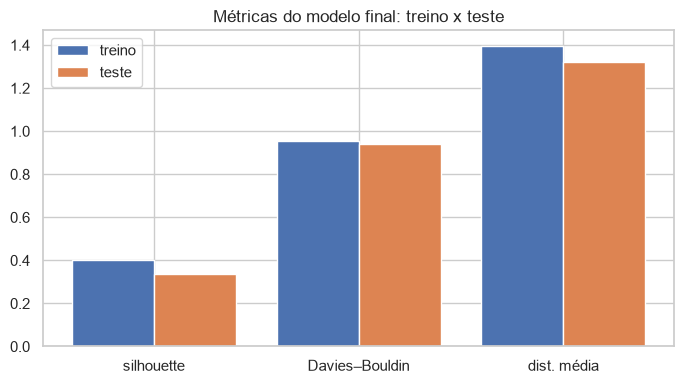

  figura: ml/figuras/06_pca_grupos.png


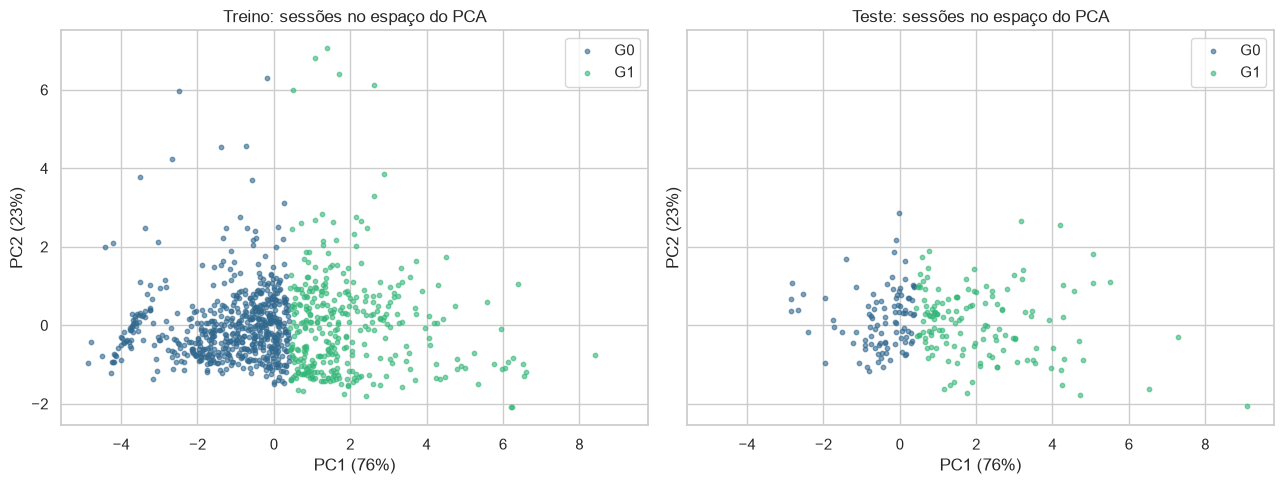

In [7]:
final = build_pipeline(**BEST).fit(X_train)
m_train, m_test = evaluate(final, X_train), evaluate(final, X_test)

raw_train, raw_test = final.predict(X_train), final.predict(X_test)
order = pd.Series(raw_train).groupby(raw_train).apply(lambda s: train.laeq.to_numpy()[s.index].mean())
relabel = {old: new for new, old in enumerate(order.sort_values().index)}
train["grupo"] = [relabel[c] for c in raw_train]
test["grupo"] = [relabel[c] for c in raw_test]

# Estabilidade: um modelo ajustado só no teste concorda com o modelo do treino?
test_only = build_pipeline(**BEST).fit(X_test)
ari_test = adjusted_rand_score(raw_test, test_only.predict(X_test))
# Estabilidade entre sementes (mesmo treino, inicializações diferentes)
ari_seeds = [
    adjusted_rand_score(raw_train, build_pipeline(**BEST, seed=s).fit(X_train).predict(X_train))
    for s in range(10)
]

metrics_table = pd.DataFrame(
    {
        "métrica": ["silhouette (↑)", "Davies–Bouldin (↓)", "distância média ao centro (↓)"],
        "treino": [m_train["silhouette"], m_train["davies_bouldin"], m_train["mean_dist"]],
        "teste": [m_test["silhouette"], m_test["davies_bouldin"], m_test["mean_dist"]],
    }
)
metrics_table["diferença"] = metrics_table.teste - metrics_table.treino
print(metrics_table.round(3).to_string(index=False))
print(f"ARI modelo-treino x modelo-só-teste: {ari_test:.3f}")
print(f"ARI entre 10 sementes: média {np.mean(ari_seeds):.3f}, mínimo {np.min(ari_seeds):.3f}")
metrics_table.to_csv(OUT_DIR / "metricas_treino_teste.csv", index=False)

pca_var = final.named_steps["pca"].explained_variance_ratio_
print("Variância explicada pelo PCA:", np.round(pca_var, 3), "total", round(pca_var.sum(), 3))
loadings = pd.DataFrame(
    final.named_steps["pca"].components_.T,
    index=FEATURES,
    columns=[f"PC{i + 1}" for i in range(BEST["n_comp"])],
)
print(loadings.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3)
ax.bar(x - 0.2, metrics_table.treino, width=0.4, label="treino")
ax.bar(x + 0.2, metrics_table.teste, width=0.4, label="teste")
ax.set_xticks(x, ["silhouette", "Davies–Bouldin", "dist. média"])
ax.set(title="Métricas do modelo final: treino x teste")
ax.legend()
save(fig, "05_treino_vs_teste.png")

palette = sns.color_palette("viridis", BEST["k"])
P_train, P_test = final[:-1].transform(X_train), final[:-1].transform(X_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, P, df, title in [(axes[0], P_train, train, "Treino"), (axes[1], P_test, test, "Teste")]:
    for g in range(BEST["k"]):
        sel = df.grupo.to_numpy() == g
        ax.scatter(P[sel, 0], P[sel, 1], s=10, alpha=0.6, color=palette[g], label=f"G{g}")
    ax.set(title=f"{title}: sessões no espaço do PCA", xlabel=f"PC1 ({pca_var[0]:.0%})",
           ylabel=f"PC2 ({pca_var[1]:.0%})")
    ax.legend()
save(fig, "06_pca_grupos.png")

## 7. Interpretação dos grupos (em dB, para o cidadão)

       laeq   p10   p50   p90  std  sessões  % treino  % teste  hora mediana
grupo                                                                       
0      54.9  47.5  51.1  56.9  3.5      698      63.4     40.9          17.0
1      68.0  60.8  64.6  70.6  4.3      487      36.6     59.1          16.0

Tags mais declaradas pelos voluntários (descritivo, não usado no modelo):
  G0: animals 49%, vegetation 48%, road 45%, chatting 40%
  G1: road 59%, chatting 42%, animals 26%, wind 23%


  figura: ml/figuras/07_niveis_por_grupo.png


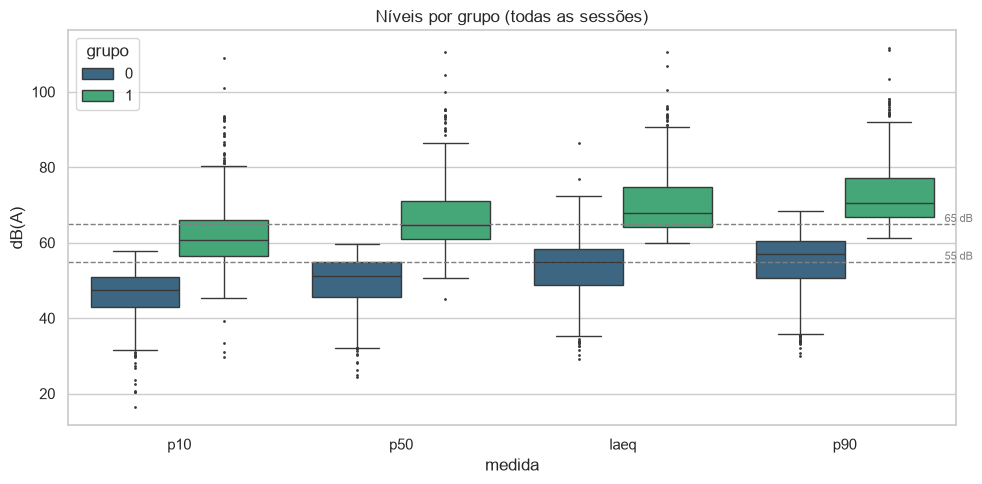

  figura: ml/figuras/08_mapa_e_horario.png


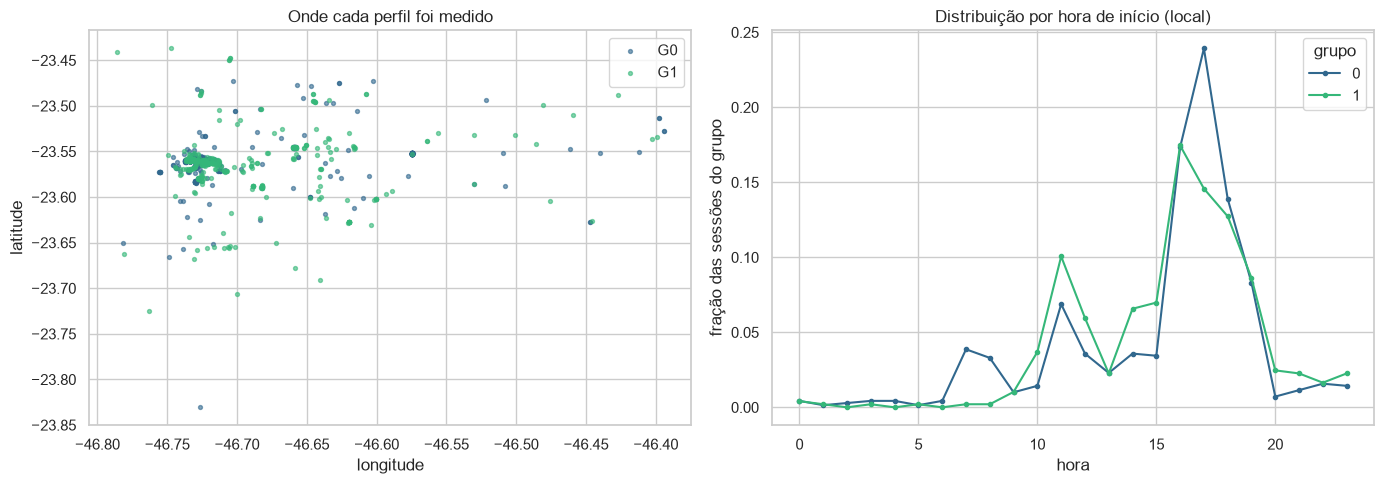

In [8]:
everyone = pd.concat([train.assign(conjunto="treino"), test.assign(conjunto="teste")])
profile = everyone.groupby("grupo")[FEATURES].median().round(1)
profile["sessões"] = everyone.groupby("grupo").size()
profile["% treino"] = (train.grupo.value_counts(normalize=True).sort_index() * 100).round(1)
profile["% teste"] = (test.grupo.value_counts(normalize=True).sort_index() * 100).round(1)
profile["hora mediana"] = everyone.groupby("grupo").hour.median()
print(profile.to_string())
profile.to_csv(OUT_DIR / "perfil_grupos.csv")

tag_share = (
    everyone.explode("tags").dropna(subset=["tags"]).groupby("grupo").tags
    .value_counts(normalize=False).groupby(level=0).head(4)
)
sessions_with_tags = everyone[everyone.tags.apply(len) > 0].groupby("grupo").size()
print("\nTags mais declaradas pelos voluntários (descritivo, não usado no modelo):")
for g in range(BEST["k"]):
    top = tag_share.loc[g] / sessions_with_tags.get(g, 1) * 100
    print(f"  G{g}: " + ", ".join(f"{t} {v:.0f}%" for t, v in top.items()))

long = everyone.melt(id_vars=["grupo"], value_vars=["p10", "p50", "laeq", "p90"],
                     var_name="medida", value_name="dB(A)")
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=long, x="medida", y="dB(A)", hue="grupo", palette=palette, ax=ax, fliersize=1)
for ref, txt in [(55, "55 dB"), (65, "65 dB")]:
    ax.axhline(ref, ls="--", lw=1, color="gray")
    ax.text(3.45, ref + 0.5, txt, color="gray", fontsize=8)
ax.set(title="Níveis por grupo (todas as sessões)")
save(fig, "07_niveis_por_grupo.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for g in range(BEST["k"]):
    sel = everyone.grupo == g
    axes[0].scatter(everyone.lon[sel], everyone.lat[sel], s=8, alpha=0.6, color=palette[g], label=f"G{g}")
axes[0].set(title="Onde cada perfil foi medido", xlabel="longitude", ylabel="latitude")
axes[0].legend()
hours = everyone.groupby(["grupo", "hour"]).size().unstack(0, fill_value=0)
(hours / hours.sum()).plot(ax=axes[1], color=palette, marker="o", ms=3)
axes[1].set(title="Distribuição por hora de início (local)", xlabel="hora", ylabel="fração das sessões do grupo")
save(fig, "08_mapa_e_horario.png")

## 8. Exportação para a API (contrato ml-summary)

In [9]:
def describe_group(g: int) -> str:
    r = profile.loc[g]
    return (
        f"LAeq mediana {r.laeq:.1f} dB(A); metade do tempo abaixo de {r.p50:.1f} dB(A); "
        f"picos (p90) de {r.p90:.1f} dB(A); variação típica {r['std']:.1f} dB."
    )


period_from = pd.to_datetime(sessions.start_ms.min(), unit="ms", utc=True)
period_to = pd.to_datetime(sessions.end_ms.max(), unit="ms", utc=True)
summary = {
    "schemaVersion": 1,
    "city": "São Paulo",
    "modelVersion": f"kmeans{BEST['k']}-pca{BEST['n_comp']}{'-whiten' if BEST['whiten'] else ''}-v1",
    "sourceUrl": SOURCE_URL,
    "datasetSha256": sha,
    "dataPeriod": {
        "from": period_from.strftime("%Y-%m-%dT%H:%M:%SZ"),
        "to": period_to.strftime("%Y-%m-%dT%H:%M:%SZ"),
    },
    "sampleCount": int(len(sessions)),
    "groups": [
        {"id": f"G{g}", "count": int(profile.loc[g, "sessões"]), "description": describe_group(g)}
        for g in range(BEST["k"])
    ],
    "metrics": [
        {"name": "silhouette", "train": round(m_train["silhouette"], 4), "test": round(m_test["silhouette"], 4)},
        {"name": "daviesBouldin", "train": round(m_train["davies_bouldin"], 4),
         "test": round(m_test["davies_bouldin"], 4)},
        {"name": "meanDistanceToCentroid", "train": round(m_train["mean_dist"], 4),
         "test": round(m_test["mean_dist"], 4)},
    ],
    "limitations": [
        "Medições voluntárias com celulares não calibrados; não são medições legais.",
        "Cobertura concentrada em poucas regiões e em 2023-2024; não representa toda a cidade.",
        "Um grupo descreve sessões medidas, não classifica automaticamente um endereço.",
        "Sessões curtas (minutos) não equivalem a indicadores de longo prazo como Lden.",
    ],
}
(OUT_DIR / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")

try:
    import jsonschema

    jsonschema.validate(summary, json.loads(SCHEMA.read_text(encoding="utf-8")))
    print("summary.json válido segundo", SCHEMA.relative_to(ROOT))
except FileNotFoundError:
    print("Schema não encontrado; summary.json gerado sem validação.")

print("\nConcluído. Resultados em ml/output/ e figuras em ml/figuras/.")

summary.json válido segundo contracts\schemas\ml-summary.schema.json

Concluído. Resultados em ml/output/ e figuras em ml/figuras/.
